# Projeto Titanic (versão simples)

**Pergunta do museu:** quais fatores influenciaram as chances de sobrevivência no Titanic?
**Dados:** `dataset-titanic.csv` (891 passageiros, 12 colunas).

| Dia | Conteúdo |
|---|---|
| **Jour 1** | Limpeza, valores ausentes, codificação |
| **Jour 2** | Feature engineering, 3 modelos, comparação |

**Como executar:** coloque este notebook e `dataset-titanic.csv` na mesma pasta. No JupyterLab: menu **Kernel → Restart Kernel and Run All Cells…**.
No Google Colab: **Ambiente de execução → Executar tudo**. Para rodar uma célula só: clique nela e aperte **Shift + Enter**.

Lembrete: tudo o que vem depois de `#` é um **comentário**. O Python ignora; está ali para explicar.

In [1]:
# Importar as bibliotecas (caixas de ferramentas prontas)
import pandas as pd                    # pandas: trabalhar com tabelas
import matplotlib.pyplot as plt        # matplotlib: desenhar gráficos
import seaborn as sns                  # seaborn: gráficos estatísticos prontos

from sklearn.model_selection import train_test_split, cross_val_score   # separar dados e validar
from sklearn.linear_model import LogisticRegression                     # modelo 1
from sklearn.ensemble import RandomForestClassifier                     # modelo 2
from xgboost import XGBClassifier                                       # modelo 3
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report  # notas

---
# JOUR 1 — Limpeza, valores ausentes e codificação

## Passo 1 · Ler o arquivo
`df` é o nome da nossa tabela (abreviação de *DataFrame*, a tabela do pandas).

In [2]:
df = pd.read_csv("dataset-titanic.csv")   # lê o arquivo e guarda a tabela em df
df.head()                                 # mostra as 5 primeiras linhas

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.shape     # tamanho da tabela: (linhas, colunas)

(891, 12)

In [4]:
df.info()    # para cada coluna: quantos valores preenchidos e o tipo (número ou texto)

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## Passo 2 · Quantos sobreviveram?

In [5]:
df["Survived"].value_counts()    # conta quantos 0 (morreu) e quantos 1 (sobreviveu)

Survived
0    549
1    342
Name: count, dtype: int64

549 morreram e 342 sobreviveram (38 %). Quem chutasse "morreu" para todos acertaria 62 % das vezes: os modelos precisam fazer melhor que isso.

## Passo 3 · Encontrar os valores ausentes

In [6]:
df.isna().sum()    # quantas células vazias em cada coluna

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Três colunas têm buracos: `Cabin` (687), `Age` (177) e `Embarked` (2). Vamos tratar uma de cada vez.

## Passo 4 · `Embarked`: preencher com o porto mais frequente

In [7]:
df["Embarked"].value_counts()    # S = Southampton é de longe o mais frequente

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [8]:
df["Embarked"] = df["Embarked"].fillna("S")   # fillna = preencher os vazios; aqui com "S"

## Passo 5 · `Age`: preencher usando o título do nome
Cada nome tem um título: "Braund, **Mr.** Owen Harris". O título dá uma boa ideia da idade
(*Master* = menino, *Miss* = moça, *Mrs* = mulher casada, *Mr* = homem adulto).

Primeiro escrevemos uma **função** que pega o título de um nome:

In [9]:
def pegar_titulo(nome):
    # nome = "Braund, Mr. Owen Harris"
    depois_da_virgula = nome.split(", ")[1]      # corta na vírgula e pega a 2ª parte: "Mr. Owen Harris"
    titulo = depois_da_virgula.split(".")[0]     # corta no ponto e pega a 1ª parte: "Mr"

    if titulo in ["Mlle", "Ms"]:                 # formas francesas de "senhorita"
        return "Miss"
    if titulo == "Mme":                          # forma francesa de "senhora"
        return "Mrs"
    if titulo in ["Mr", "Mrs", "Miss", "Master"]:
        return titulo
    return "Rare"                                # Dr, Rev, Col, Countess... (poucos passageiros)

pegar_titulo("Braund, Mr. Owen Harris")          # teste: deve mostrar 'Mr'

'Mr'

In [10]:
df["Title"] = df["Name"].apply(pegar_titulo)     # .apply aplica a função a cada nome -> nova coluna Title
df["Title"].value_counts()

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

In [11]:
medianas = df.groupby("Title")["Age"].median()   # idade mediana de cada título
medianas

Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64

In [12]:
# .map(medianas) troca cada título pela idade mediana dele; fillna usa isso só onde a idade está vazia
df["Age"] = df["Age"].fillna(df["Title"].map(medianas))
print("Idades vazias:", df["Age"].isna().sum())    # deve dar 0

Idades vazias: 0


## Passo 6 · `Cabin`: guardar só "tem cabine ou não"
A coluna está vazia em 77 % das linhas: impossível adivinhar. Mas **ter** uma cabine registrada já diz algo.

In [13]:
df["HasCabin"] = df["Cabin"].notna().astype(int)   # 1 se a cabine é conhecida, 0 se não
df.groupby("HasCabin")["Survived"].mean()          # taxa de sobrevivência em cada grupo

HasCabin
0    0.299854
1    0.666667
Name: Survived, dtype: float64

## Passo 6b · Olhar os valores extremos (outliers)
Um valor extremo é um valor muito longe dos outros. Antes de apagar, é preciso entender se é um erro ou um caso real.

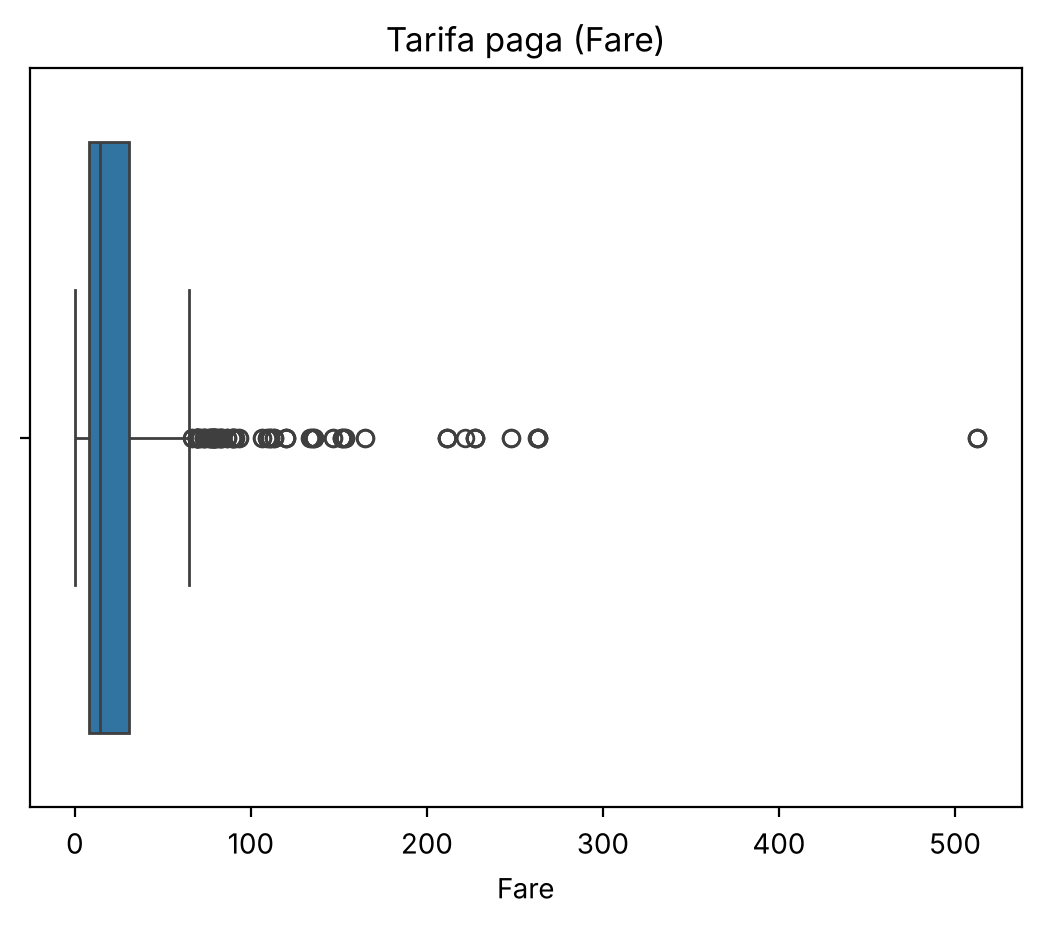

In [14]:
sns.boxplot(x=df["Fare"])          # boxplot: a caixa mostra o "meio" dos dados; os pontos isolados são os extremos
plt.title("Tarifa paga (Fare)")
plt.show()

In [15]:
q1 = df["Fare"].quantile(0.25)     # 25 % dos passageiros pagaram menos que isto
q3 = df["Fare"].quantile(0.75)     # 75 % pagaram menos que isto
limite = q3 + 1.5 * (q3 - q1)      # regra do IQR: acima deste valor é "extremo"
print("Limite:", limite)
print("Tarifas acima do limite:", (df["Fare"] > limite).sum())
print("Idade mínima:", df["Age"].min(), "| Idade máxima:", df["Age"].max())

Limite: 65.6344
Tarifas acima do limite: 116
Idade mínima: 0.42 | Idade máxima: 80.0


**Decisão: manter.** As tarifas altas são bilhetes de luxo reais (1ª classe) e as idades vão de 0,42 a 80 anos: nada de errado.

## Passo 7 · Apagar as colunas inúteis

In [16]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])   # drop = apagar
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,0


- `PassengerId`: só um número de linha.
- `Ticket`: quase um valor diferente por passageiro.
- `Name`: já tiramos o título.
- `Cabin`: substituída por `HasCabin`.

## Passo 8 · Transformar o texto em números (codificação)
Os modelos só entendem números.

In [17]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})   # homem = 0, mulher = 1

In [18]:
# one-hot: cada porto e cada título vira uma coluna de 0 e 1 (Embarked_C, Embarked_Q, Embarked_S, Title_Mr...)
df = pd.get_dummies(df, columns=["Embarked", "Title"], dtype=int)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,1,0,7.2500,0,0,0,1,0,0,1,0,0
1,1,1,1,38.0,1,0,71.2833,1,1,0,0,0,0,0,1,0
2,1,3,1,26.0,0,0,7.9250,0,0,0,1,0,1,0,0,0
3,1,1,1,35.0,1,0,53.1000,1,0,0,1,0,0,0,1,0
4,0,3,0,35.0,0,0,8.0500,0,0,0,1,0,0,1,0,0


In [19]:
print("Células vazias:", df.isna().sum().sum())   # total de células vazias: deve dar 0
df.to_csv("titanic_clean.csv", index=False)       # salva a tabela limpa num arquivo
print("Arquivo salvo: titanic_clean.csv")

Células vazias: 0
Arquivo salvo: titanic_clean.csv


**Fim do Jour 1:** a tabela está limpa, sem vazios e só com números.

---
# JOUR 2 — Feature engineering, modelos e comparação

## Passo 9 · Criar variáveis novas

In [20]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1     # tamanho da família a bordo (+1 = a própria pessoa)
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)  # 1 se viaja sozinho, 0 se não

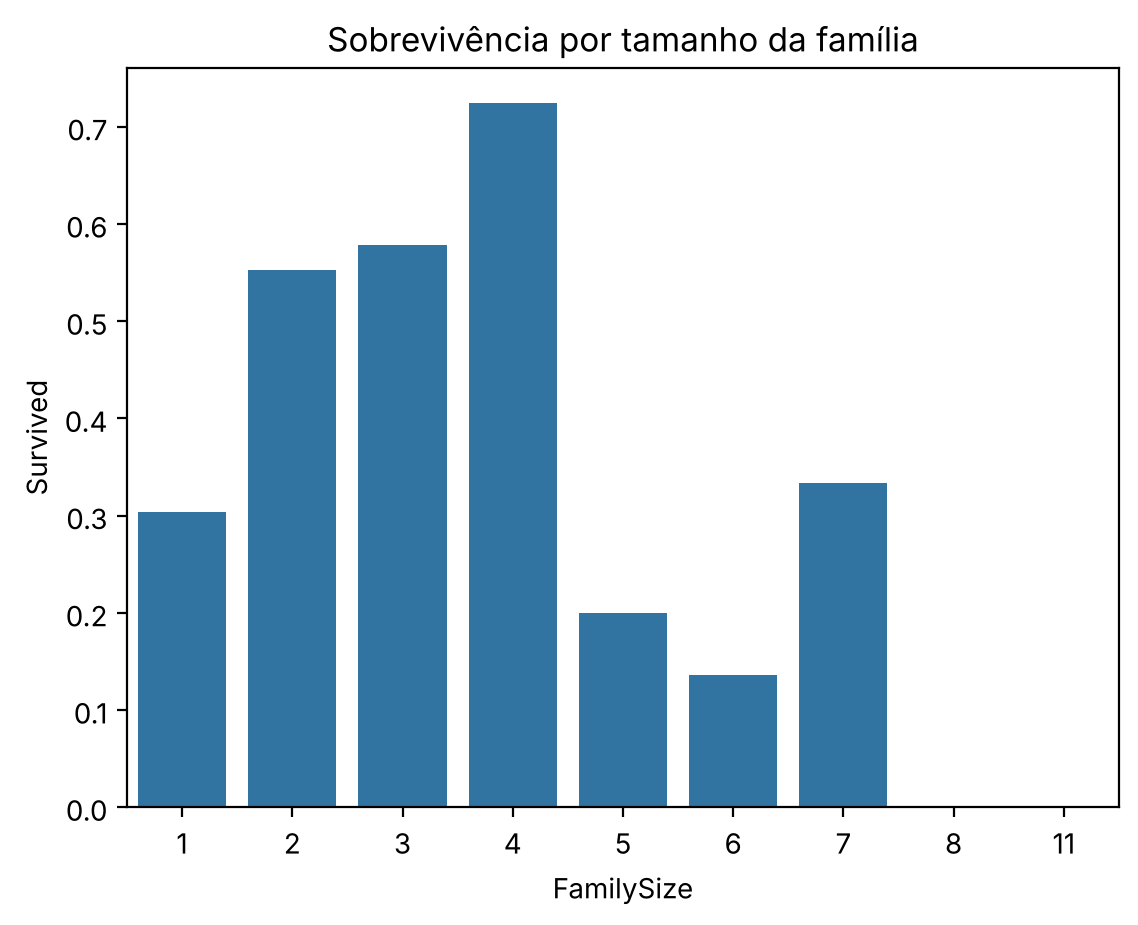

In [21]:
sns.barplot(data=df, x="FamilySize", y="Survived", errorbar=None)   # altura da barra = taxa de sobrevivência
plt.title("Sobrevivência por tamanho da família")
plt.show()

## Passo 10 · Separar as perguntas (X) da resposta (y)

In [22]:
X = df.drop(columns=["Survived"])   # X = todas as colunas menos a resposta
y = df["Survived"]                  # y = a resposta: sobreviveu ou não

## Passo 11 · Separar treino e teste
O modelo **aprende** com o treino (80 %) e é **avaliado** no teste (20 %), que ele nunca viu.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20 % para o teste
    stratify=y,          # mesma proporção de sobreviventes nos dois
    random_state=42,     # sorteio fixo: resultados sempre iguais
)
print("Treino:", len(X_train), "passageiros | Teste:", len(X_test), "passageiros")

Treino: 712 passageiros | Teste: 179 passageiros


## Passo 12 · Modelo 1: regressão logística
Sempre os mesmos 3 passos: **criar** o modelo, **treinar** (`fit`), **prever** (`predict`).

In [24]:
modelo_lr = LogisticRegression(max_iter=1000)   # 1. criar
modelo_lr.fit(X_train, y_train)                 # 2. treinar com o treino
previsao_lr = modelo_lr.predict(X_test)         # 3. prever o teste

print("Accuracy:", accuracy_score(y_test, previsao_lr))   # % de acertos
print("F1:", f1_score(y_test, previsao_lr))               # equilíbrio entre precisão e recall

Accuracy: 0.8435754189944135
F1: 0.7941176470588235


## Passo 13 · Modelo 2: Random Forest

In [25]:
modelo_rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)   # 300 árvores
modelo_rf.fit(X_train, y_train)
previsao_rf = modelo_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, previsao_rf))
print("F1:", f1_score(y_test, previsao_rf))

Accuracy: 0.8156424581005587
F1: 0.7401574803149606


In [25]:
modelo_rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42)   # 300 árvores
modelo_rf.fit(X_train, y_train)
previsao_rf = modelo_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, previsao_rf))
print("F1:", f1_score(y_test, previsao_rf))

Accuracy: 0.8156424581005587
F1: 0.7401574803149606


## Passo 14 · Modelo 3: XGBoost

In [26]:
modelo_xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
modelo_xgb.fit(X_train, y_train)
previsao_xgb = modelo_xgb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, previsao_xgb))
print("F1:", f1_score(y_test, previsao_xgb))

Accuracy: 0.8100558659217877
F1: 0.7424242424242424


In [26]:
modelo_xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
modelo_xgb.fit(X_train, y_train)
previsao_xgb = modelo_xgb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, previsao_xgb))
print("F1:", f1_score(y_test, previsao_xgb))

Accuracy: 0.8100558659217877
F1: 0.7424242424242424


## Passo 15 · Comparar os 3 modelos

In [27]:
resultados = pd.DataFrame({
    "modelo":   ["Regressão logística", "Random Forest", "XGBoost"],
    "accuracy": [accuracy_score(y_test, previsao_lr), accuracy_score(y_test, previsao_rf), accuracy_score(y_test, previsao_xgb)],
    "f1":       [f1_score(y_test, previsao_lr),       f1_score(y_test, previsao_rf),       f1_score(y_test, previsao_xgb)],
})
resultados

,modelo,accuracy,f1
0,Regressão logística,0.843575,0.794118
1,Random Forest,0.815642,0.740157
2,XGBoost,0.810056,0.742424


### Uma checagem extra: validação cruzada
Um único teste pode ter sorte ou azar. A validação cruzada treina 5 vezes em pedaços diferentes do treino e faz a média.

In [28]:
print("Regressão logística:", cross_val_score(modelo_lr, X_train, y_train, cv=5).mean())
print("Random Forest:      ", cross_val_score(modelo_rf, X_train, y_train, cv=5).mean())
print("XGBoost:            ", cross_val_score(modelo_xgb, X_train, y_train, cv=5).mean())

Regressão logística: 0.8160445188614203


Random Forest:       0.8216783216783217


XGBoost:             0.8273121244952231


## Passo 16 · As variáveis novas ajudaram?
Treinamos a regressão logística duas vezes: só com as colunas originais, e com tudo.

In [29]:
colunas_originais = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked_C", "Embarked_Q", "Embarked_S"]

sem_novas = cross_val_score(LogisticRegression(max_iter=1000), X_train[colunas_originais], y_train, cv=5).mean()
com_novas = cross_val_score(LogisticRegression(max_iter=1000), X_train, y_train, cv=5).mean()
print("Só colunas originais:", sem_novas)
print("Com as variáveis novas:", com_novas)

Só colunas originais: 0.8020289569585344
Com as variáveis novas: 0.8160445188614203


## Passo 17 · Onde o melhor modelo erra? (matriz de confusão)

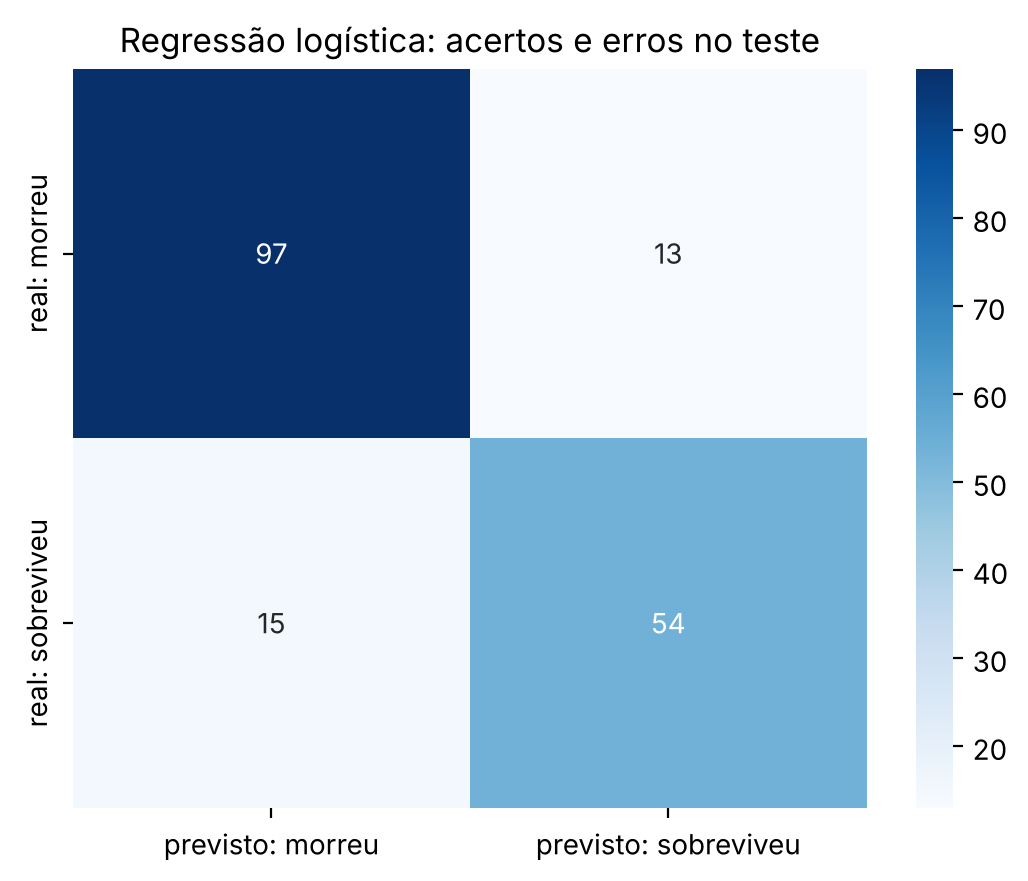

In [30]:
matriz = confusion_matrix(y_test, previsao_lr)
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
            xticklabels=["previsto: morreu", "previsto: sobreviveu"],
            yticklabels=["real: morreu", "real: sobreviveu"])
plt.title("Regressão logística: acertos e erros no teste")
plt.show()

In [31]:
print(classification_report(y_test, previsao_lr))   # precisão, recall e F1 de cada classe

              precision    recall  f1-score   support

           0       0.87      0.88      0.87       110
           1       0.81      0.78      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



## Passo 18 · Quais variáveis pesam mais?

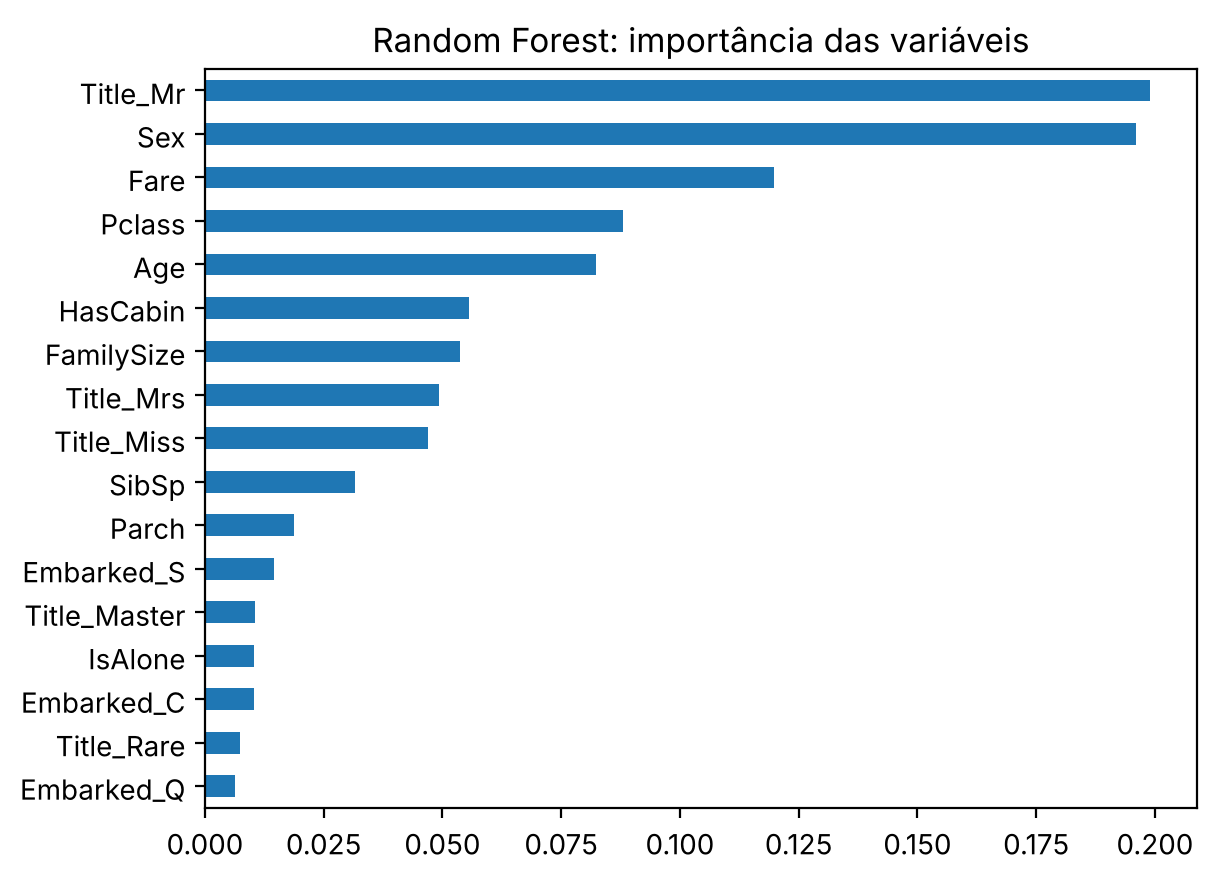

In [32]:
importancia = pd.Series(modelo_rf.feature_importances_, index=X.columns)   # importância de cada coluna
importancia.sort_values().plot.barh()                                      # gráfico de barras deitadas
plt.title("Random Forest: importância das variáveis")
plt.show()

## Conclusão
- **Sexo**: o fator nº 1 (74 % das mulheres sobreviveram, 19 % dos homens).
- **Idade / título**: as crianças, sobretudo os meninos (*Master*), tiveram prioridade.
- **Classe**: 63 % de sobrevivência na 1ª classe, 24 % na 3ª.
- **Família**: famílias de 2 a 4 pessoas se saíram melhor que quem estava sozinho ou em família grande.

Os três modelos têm resultados próximos. A **regressão logística** é a mais simples de explicar ao público do museu.